In [1]:
import matplotlib.pyplot as plt
from helpers import *
from preprocessing import *
from training import *
from postprocessing import *

%load_ext autoreload
%autoreload 2

In [2]:
data_path = "./data/dataset"

In [3]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path, sub_sample=False)

header = check_header(x_train, data_path)

Header okay!


In [4]:
print(np.shape(x_train))
print(np.shape(x_test))

(328135, 321)
(109379, 321)


In [5]:
# imputation settings as hyperparameters (cross-validation with features built inside each fold)
k_indices = build_k_indices(y_train, k_fold=5, seed=0)
configs = {
    "base":              {"categorical": "none", "discrete": "median", "continuous": "median"},
    "categorical mode":  {"categorical": "mode", "discrete": "median", "continuous": "median"},
    "discrete mode":     {"categorical": "none", "discrete": "mode",   "continuous": "median"},
    "discrete random":   {"categorical": "none", "discrete": "random", "continuous": "median"},
    "continuous random": {"categorical": "none", "discrete": "median", "continuous": "random"},
}

config_results = {}
for config_name, impute_settings in configs.items():
    res = cross_validation_features(y_train, x_train, header, k_indices, impute_settings,
                                    lambda_=1e-4, gamma=0.001, max_epochs=30)
    config_results[config_name] = res
    print(f"{config_name:18} | val loss: {res['val_loss']:.5f} | "
          f"threshold: {res['threshold']:.2f} | F1: {res['f1']:.4f}")

best_config = max(config_results, key=lambda c: config_results[c]["f1"])
best_impute_settings = configs[best_config]
print("Best imputation setting:", best_config)

base               | val loss: 0.22018 | threshold: 0.20 | F1: 0.4324
categorical mode   | val loss: 0.22022 | threshold: 0.20 | F1: 0.4324
discrete mode      | val loss: 0.22018 | threshold: 0.20 | F1: 0.4324
discrete random    | val loss: 0.22030 | threshold: 0.20 | F1: 0.4321
continuous random  | val loss: 0.22025 | threshold: 0.20 | F1: 0.4321
Best imputation setting: base


In [6]:
# missingness threshold for dropping features, with the best imputation setting
threshold_results = {1: config_results[best_config]}   # 1 already evaluated above

for t in [0.95, 0.9, 0.8, 0.7, 0.6]:
    x_train_t, _, header_t = drop_high_missing_features(x_train, x_test, header, threshold=t)
    res = cross_validation_features(y_train, x_train_t, header_t, k_indices, best_impute_settings,
                                    lambda_=1e-4, gamma=0.001, max_epochs=30)
    threshold_results[t] = res
    print(f"missingness threshold {t:.2f} | features: {len(header_t)} | "
          f"val loss: {res['val_loss']:.5f} | F1: {res['f1']:.4f}")

best_missing_threshold = max(threshold_results, key=lambda t: threshold_results[t]["f1"])
print("Best missingness threshold:", best_missing_threshold)

# continue the rest of the notebook with the columns of the best threshold
x_train, x_test, header = drop_high_missing_features(x_train, x_test, header, threshold=best_missing_threshold)

missingness threshold 0.95 | features: 253 | val loss: 0.22103 | F1: 0.4298
missingness threshold 0.90 | features: 222 | val loss: 0.22133 | F1: 0.4291
missingness threshold 0.80 | features: 205 | val loss: 0.22151 | F1: 0.4279
missingness threshold 0.70 | features: 200 | val loss: 0.22160 | F1: 0.4277
missingness threshold 0.60 | features: 192 | val loss: 0.22167 | F1: 0.4276
Best missingness threshold: 1


In [7]:
# build features on train, then apply the same encoding to test
X_train, X_test, feature_names = build_feature_matrix(x_train, x_test, header, best_impute_settings)

# add bias column
tx_train = add_bias(X_train)
tx_test = add_bias(X_test)

# sanity checks
print("Train:", tx_train.shape, "| Test:", tx_test.shape)  # same number of columns
print("NaN in X?", np.isnan(tx_train).any(), np.isnan(tx_test).any())  # False, False
print("y values:", np.unique(y_train, return_counts=True))  # -1 / 1, about 9% of 1

Train: (328135, 904) | Test: (109379, 904)
NaN in X? False False
y values: (array([-1,  1]), array([299160,  28975]))


In [8]:
# compute_loss test

w0 = np.zeros(tx_train.shape[1])
print("Loss at w=0:", compute_loss(y_train, tx_train, w0), "| log(2) =", np.log(2))

Loss at w=0: 0.6931471805599453 | log(2) = 0.6931471805599453


In [9]:
# compute_gardient test

# random w to avoid the trivial point w=0
rng = np.random.default_rng(0)
w = rng.normal(scale=0.01, size=tx_train.shape[1])
lambda_ = 0.1
eps = 1e-6

# loss including the ridge penalty (bias not penalized), to match compute_gradient
def full_loss(w):
    return compute_loss(y_train, tx_train, w) + lambda_ * np.sum(w[1:] ** 2)

grad = compute_gradient(y_train, tx_train, w, lambda_)
for i in [0, 1, 5, 10]:
    e = np.zeros_like(w)
    e[i] = eps
    num_grad = (full_loss(w + e) - full_loss(w - e)) / (2 * eps)
    print(f"coord {i:3d} | analytic: {grad[i]: .8f} | numerical: {num_grad: .8f}")

coord   0 | analytic:  0.40274808 | numerical:  0.40274808
coord   1 | analytic:  0.00659242 | numerical:  0.00659242
coord   5 | analytic:  0.01308602 | numerical:  0.01308602
coord  10 | analytic:  0.00724795 | numerical:  0.00724795


In [10]:
tx_tr, tx_val, y_tr, y_val = split_data(tx_train, y_train, ratio=0.8, seed=0)
print("Train part:", tx_tr.shape, "| Validation part:", tx_val.shape)
print("Positives in train part:", np.mean(y_tr == 1), "| in validation part:", np.mean(y_val == 1))

Train part: (262508, 904) | Validation part: (65627, 904)
Positives in train part: 0.08817255093178113 | in validation part: 0.08882015024304021


In [11]:
# choosing the training procedure on the 80/20 split, diagnostic only
sgd_settings = {"gamma=0.001": dict(gamma=0.001), "gamma=0.01": dict(gamma=0.01), "gamma=0.0001": dict(gamma=0.0001)}

histories = {}
for label, settings in sgd_settings.items():
    _, histories[label] = sgd_logistic(y_tr, tx_tr, 1e-4, np.zeros(tx_tr.shape[1]), max_epochs=150, batch_size=32, tx_val=tx_val, y_val=y_val, verbose=False, **settings)

# losses at the epoch budgets of interest, and how much the training loss still moves at the end
for label, h in histories.items():
    train, val = np.array(h["train_loss"]), np.array(h["val_loss"])
    print(f"{label}, val loss at 15/50/100/150: "
          + " / ".join(f"{val[e - 1]:.5f}" for e in [15, 50, 100, 150])
          + f" | train loss change over last 10 epochs: {train[-11] - train[-1]:.1e}")

gamma=0.001, val loss at 15/50/100/150: 0.22206 / 0.22043 / 0.21987 / 0.21949 | train loss change over last 10 epochs: 4.3e-05
gamma=0.01, val loss at 15/50/100/150: 0.22289 / 0.22024 / 0.22009 / 0.22256 | train loss change over last 10 epochs: -3.4e-03
gamma=0.0001, val loss at 15/50/100/150: 0.22764 / 0.22350 / 0.22213 / 0.22161 | train loss change over last 10 epochs: 1.0e-04


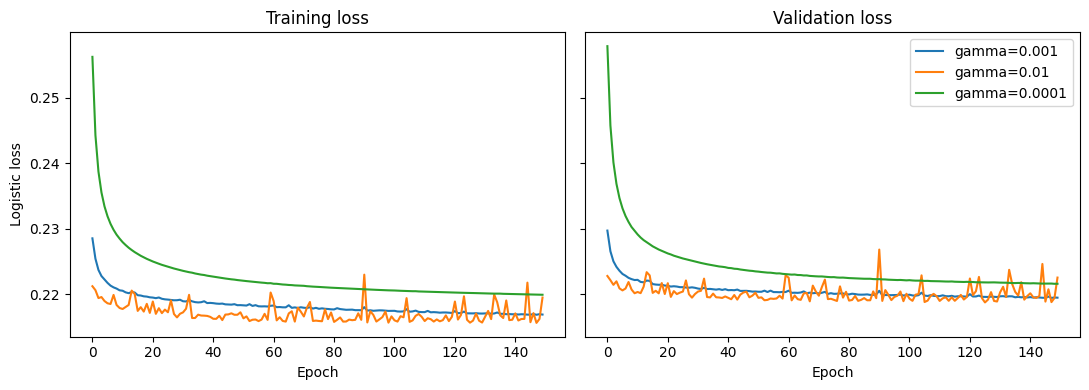

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for label, h in histories.items():
    axes[0].plot(h["train_loss"], label=label)
    axes[1].plot(h["val_loss"], label=label)
for ax, title in zip(axes, ["Training loss", "Validation loss"]):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Logistic loss")
axes[1].legend()
plt.tight_layout()
plt.show()

In [13]:
w_init = np.zeros(tx_tr.shape[1])

w, history = sgd_logistic(
    y_tr, tx_tr,
    lambda_= 0,
    initial_w=w_init,
    max_epochs=100,
    gamma=0.001,
    batch_size=32,
    tx_val=tx_val, y_val=y_val,
)

epoch   1/100 | train loss: 0.22854 | val loss: 0.22972
epoch   2/100 | train loss: 0.22543 | val loss: 0.22656
epoch   3/100 | train loss: 0.22371 | val loss: 0.22503
epoch   4/100 | train loss: 0.22277 | val loss: 0.22418
epoch   5/100 | train loss: 0.22225 | val loss: 0.22358
epoch   6/100 | train loss: 0.22173 | val loss: 0.22309
epoch   7/100 | train loss: 0.22131 | val loss: 0.22282
epoch   8/100 | train loss: 0.22104 | val loss: 0.22250
epoch   9/100 | train loss: 0.22086 | val loss: 0.22230
epoch  10/100 | train loss: 0.22059 | val loss: 0.22216
epoch  11/100 | train loss: 0.22053 | val loss: 0.22219
epoch  12/100 | train loss: 0.22028 | val loss: 0.22188
epoch  13/100 | train loss: 0.22015 | val loss: 0.22182
epoch  14/100 | train loss: 0.22032 | val loss: 0.22208
epoch  15/100 | train loss: 0.22025 | val loss: 0.22204
epoch  16/100 | train loss: 0.21984 | val loss: 0.22155
epoch  17/100 | train loss: 0.21979 | val loss: 0.22147
epoch  18/100 | train loss: 0.21967 | val loss: 

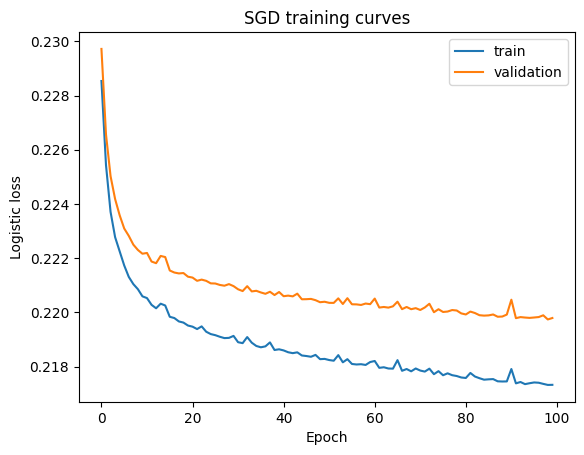

In [14]:
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Logistic loss")
plt.title("SGD training curves")
plt.legend()
plt.show()

In [15]:
# baseline: always predict -1 (not sick)
y_baseline = -np.ones_like(y_val)
print("Baseline (always -1):", compute_metrics(y_val, y_baseline))

# model with the default threshold 0.5
y_pred_05 = predict_labels(tx_val, w, threshold=0.5)
print("Model, threshold 0.5: ", compute_metrics(y_val, y_pred_05))

Baseline (always -1): {'accuracy': 0.9111798497569598, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
Model, threshold 0.5:  {'accuracy': 0.9154616240266963, 'precision': 0.5835812016656752, 'recall': 0.1682964487905301, 'f1': 0.2612516644474035}


Best threshold: 0.21 | F1: 0.4363
Model, best threshold: {'accuracy': 0.8758590214393466, 'precision': 0.36560760667903525, 'recall': 0.5409161091096243, 'f1': 0.43631080052584237}


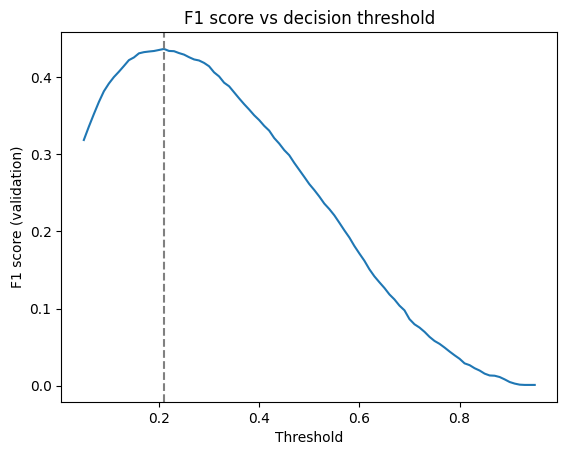

In [16]:
proba_val = predict_proba(tx_val, w)
thresholds = np.linspace(0.05, 0.95, 91)
best_t, best_f1, f1_scores = find_best_threshold(y_val, proba_val, thresholds)

print(f"Best threshold: {best_t:.2f} | F1: {best_f1:.4f}")
print("Model, best threshold:", compute_metrics(y_val, predict_labels(tx_val, w, best_t)))

plt.plot(thresholds, f1_scores)
plt.axvline(best_t, linestyle="--", color="gray")
plt.xlabel("Threshold")
plt.ylabel("F1 score (validation)")
plt.title("F1 score vs decision threshold")
plt.show()

In [17]:
k_indices = build_k_indices(y_train, k_fold=5, seed=0)
lambdas = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

results = []
for lambda_ in lambdas:
    res = cross_validation(y_train, tx_train, k_indices, lambda_, gamma=0.001, max_epochs=100)
    results.append(res)
    print(f"lambda = {lambda_:.0e} | val loss: {res['val_loss']:.5f} | "
          f"threshold: {res['threshold']:.2f} | F1: {res['f1']:.4f}")

best = max(results, key=lambda r: r["f1"])
print("\nBest:", best)

lambda = 0e+00 | val loss: 0.21898 | threshold: 0.21 | F1: 0.4358
lambda = 1e-05 | val loss: 0.21899 | threshold: 0.21 | F1: 0.4357
lambda = 1e-04 | val loss: 0.21907 | threshold: 0.21 | F1: 0.4356
lambda = 1e-03 | val loss: 0.21990 | threshold: 0.22 | F1: 0.4334
lambda = 1e-02 | val loss: 0.22378 | threshold: 0.20 | F1: 0.4225
lambda = 1e-01 | val loss: 0.23754 | threshold: 0.17 | F1: 0.4002

Best: {'lambda': 0, 'val_loss': np.float64(0.2189761604461756), 'threshold': np.float64(0.20999999999999996), 'f1': 0.43575710190252803}


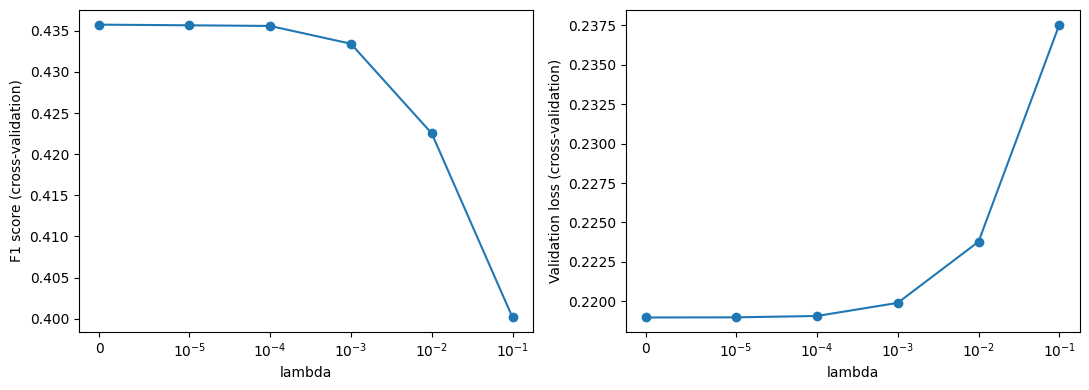

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(lambdas, [r["f1"] for r in results], marker="o")
axes[0].set_ylabel("F1 score (cross-validation)")

axes[1].plot(lambdas, [r["val_loss"] for r in results], marker="o")
axes[1].set_ylabel("Validation loss (cross-validation)")

for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-5)  # symlog so that lambda = 0 can be shown
    ax.set_xlabel("lambda")

plt.tight_layout()
plt.show()

In [ ]:
# final model: trained on the full train set with the lambda and threshold selected by cross-validation

w_final, _ = sgd_logistic(y_train, tx_train, best["lambda"], np.zeros(tx_train.shape[1]), max_epochs=150, gamma=0.001, verbose=False)
y_pred = predict_labels(tx_test, w_final, threshold=best["threshold"])

# sanity checks before writing the file
print("Shapes:", y_pred.shape, test_ids.shape)  # must be equal
print("Values:", np.unique(y_pred, return_counts=True))  # only -1 and 1
print("Share predicted sick:", np.mean(y_pred == 1))  # around 10-15% expected

# write the submission file (columns: Id, Prediction)
create_csv_submission(test_ids, y_pred, "submission_test.csv")

Shapes: (109379,) (109379,)
Values: (array([-1,  1]), array([94942, 14437]))
Share predicted sick: 0.1319906014865742


Best threshold: 0.19 | F1: 0.4399
Model, best threshold: {'accuracy': 0.8659393237539428, 'precision': 0.3470376094796497, 'recall': 0.5778006519128496, 'f1': 0.4336294579631776}


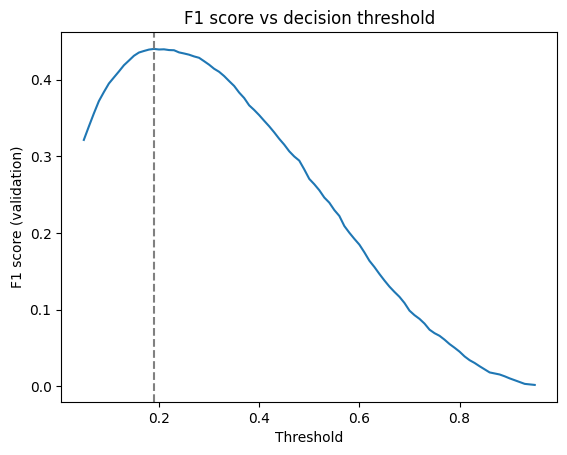

In [ ]:
# Threshold Verification

proba_val = predict_proba(tx_val, w_final)
thresholds = np.linspace(0.05, 0.95, 91)
best_t, best_f1, f1_scores = find_best_threshold(y_val, proba_val, thresholds)

print(f"Best threshold: {best_t:.2f} | F1: {best_f1:.4f}")
print("Model, best threshold:", compute_metrics(y_val, predict_labels(tx_val, w, best_t)))

plt.plot(thresholds, f1_scores)
plt.axvline(best_t, linestyle="--", color="gray")
plt.xlabel("Threshold")
plt.ylabel("F1 score (validation)")
plt.title("F1 score vs decision threshold")
plt.show()